# Jointure

Les données sont chargé `../data_cleans/`, on crée une nouvelle jointure en se basant sur les iris et on enregistre dans `../save/`.
On a pas utilisé la méthoden de l'héxagone et on est resté sur geojson a qui on rajouté nos données.


# Bibliotheque

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display

# Variables Gloabales

In [2]:
# Chemins
CLEAN_DIR = "../data_cleans/"
SAVE_DIR = "../save/"

L93 = 2154 

# Liste des espaces verts non visitables
EV_NON_VISITABLES = ["jardiniere", "mur", "talus", "decoration", "plate-bande", "terre-plein"]

MODES_GTFS = {0: "tram", 1: "metro", 2: "train", 3: "bus"}  

TOP_LIEUX = 15

# Normalisation des noms de colonnes
NIVEAUX = {"Ecole": "ecole", "Collège": "college", "Lycée": "lycee"}
COLUMNS_VA_COLLEGES = {"Taux de réussite G": "college_taux_reussite", "VA du taux de réussite G": "college_va_reussite",
                       "Note à l'écrit G": "college_note_ecrit", "Taux d'accès 6eme 3eme": "college_taux_acces_6e_3e"}

#dictionnaire entre les codes et la correspondances du code 
FAMILLES_NAF = {  
    "nb_commerces_alimentaires": ("47.11", "47.2"),
    "nb_commerces_detail": ("47.1", "47.2", "47.3", "47.4", "47.5", "47.6", "47.7", "47.8"), 
    "nb_restaurants_bars": ("56.",),
    "nb_sante": ("86.",),
    "nb_services_personnels": ("96.01", "96.02", "96.04"), 
}

COMMERCES_NAF = { 
    "supermarche": ("47.11D", "47.11F"),  
    "superette": ("47.11B", "47.11C"), 
    "boulangerie": ("10.71C", "10.71D", "47.24Z"),
    "boucherie_poissonnerie": ("47.22Z", "47.23Z"),
    "primeur": ("47.21Z",),
    "pharmacie": ("47.73Z",),
    "medecin": ("86.21Z",), 
    "dentiste": ("86.23Z",),
    "creche": ("88.91A",),
    "salle_sport": ("93.13Z",),
    "cinema": ("59.14Z",),
    "librairie": ("47.61Z", "47.62Z"), 
    "bureau_poste": ("53.10Z",),
    "pressing_laverie": ("96.01A", "96.01B"),
    "veterinaire": ("75.00Z",),
}

RP_OCCUPATION = ["C22_RP_NORME", "C22_RP_SUROCC_MOD", "C22_RP_SUROCC_ACC", "C22_RP_SOUSOCC_MOD", "C22_RP_SOUSOCC_ACC", "C22_RP_SOUSOCC_TACC"]

LOGEMENT_PARTS = { 
    "part_proprietaires_%": (["P22_RP_PROP"], ["P22_RP"]),
    "part_locataires_%": (["P22_RP_LOC"], ["P22_RP"]),
    "part_hlm_%": (["P22_RP_LOCHLMV"], ["P22_RP"]),
    "part_maisons_%": (["P22_MAISON"], ["P22_LOG"]),
    "part_logements_vacants_%": (["P22_LOGVAC"], ["P22_LOG"]),
    "part_residences_secondaires_%": (["P22_RSECOCC"], ["P22_LOG"]),
    "part_1_2_pieces_%": (["P22_RP_1P", "P22_RP_2P"], ["P22_RP"]),
    "part_5_pieces_plus_%": (["P22_RP_5PP"], ["P22_RP"]),
    "part_100m2_plus_%": (["P22_RP_100120M2", "P22_RP_120M2P"], ["P22_RP"]),
    "part_avant_1946_%": (["P22_RP_ACH1919", "P22_RP_ACH1945"], ["P22_RP_ACHTOT"]),
    "part_2006_2018_%": (["P22_RP_ACH2019"], ["P22_RP_ACHTOT"]),
    "part_emmenages_10ans_plus_%": (["P22_MEN_ANEM10P"], ["P22_MEN"]),
    "part_menages_voiture_%": (["P22_RP_VOIT1P"], ["P22_RP"]),
    "part_menages_parking_%": (["P22_RP_GARL"], ["P22_RP"]),
    "part_suroccupation_%": (["C22_RP_SUROCC_MOD", "C22_RP_SUROCC_ACC"], RP_OCCUPATION),
    "part_sousoccupation_%": (["C22_RP_SOUSOCC_MOD", "C22_RP_SOUSOCC_ACC", "C22_RP_SOUSOCC_TACC"], RP_OCCUPATION),
}

ACTIVITE_PARTS = {  
    "taux_activite_%": (["P22_ACT1564"], ["P22_POP1564"]),
    "taux_chomage_%": (["P22_CHOM1564"], ["P22_ACT1564"]),
    "part_15_24_ans_%": (["P22_POP1524"], ["P22_POP1564"]),
    "part_55_64_ans_%": (["P22_POP5564"], ["P22_POP1564"]),
    "part_etudiants_%": (["P22_ETUD1564"], ["P22_POP1564"]),
    "part_retraites_15_64_%": (["P22_RETR1564"], ["P22_POP1564"]),
    "part_artisans_commercants_%": (["C22_ACT1564_STAT_GSEC12_22"], ["C22_ACT1564"]),
    "part_cadres_%": (["C22_ACT1564_STAT_GSEC13_23"], ["C22_ACT1564"]),
    "part_professions_intermediaires_%": (["C22_ACT1564_STAT_GSEC14_24"], ["C22_ACT1564"]),
    "part_employes_%": (["C22_ACT1564_STAT_GSEC15_25"], ["C22_ACT1564"]),
    "part_ouvriers_%": (["C22_ACT1564_STAT_GSEC16_26"], ["C22_ACT1564"]),
    "part_non_salaries_%": (["P22_NSAL15P"], ["P22_ACTOCC15P"]),
    "part_salaries_temps_partiel_%": (["P22_SAL15P_TP"], ["P22_SAL15P"]),
    "part_travail_commune_residence_%": (["P22_ACTOCC15P_ILT1"], ["P22_ACTOCC15P"]),
    "part_trajet_transports_commun_%": (["C22_ACTOCC15P_TCOM"], ["C22_ACTOCC15P"]),
    "part_trajet_voiture_%": (["C22_ACTOCC15P_VOIT"], ["C22_ACTOCC15P"]),
    "part_trajet_velo_%": (["C22_ACTOCC15P_VELO"], ["C22_ACTOCC15P"]),
    "part_trajet_marche_%": (["C22_ACTOCC15P_MAR"], ["C22_ACTOCC15P"]),
}

In [3]:
data = {}


for f in sorted(os.listdir(CLEAN_DIR)):
    path = os.path.join(CLEAN_DIR, f)

    if f.endswith(".geojson"):
        data[f] = gpd.read_file(path)

    elif f.endswith(".parquet"):
        data[f] = pd.read_parquet(path)

display(pd.DataFrame({f: df.shape for f, df in data.items()}, index=["lignes", "colonnes"]).T)

,lignes,colonnes
AirBruit_2024.geojson,165704,2
base-ic-activite-residents-2022.parquet,992,25
base-ic-logement-2022.parquet,992,30
calendar.parquet,613,10
calendar_dates.parquet,1266,3
espaces_verts.parquet,2517,9
fr-en-annuaire-education.geojson,1459,10
fr-en-indicateurs-valeur-ajoutee-colleges.parquet,171,7
fr-en-ips-ecoles-ap2022.parquet,447,4
fr-en-ips-lycees-ap2023.parquet,157,4


In [4]:
# Gestion du code iris pour pour le grains de nos résultats 

iris = data["iris.geojson"].drop(columns="id").to_crs(L93).set_index("code_iris")

iris["code_postal"] = (iris["insee_com"] - 100).astype(str)

iris["surface_iris_km2"] = iris.area / 1e6

iris = iris.join(data["iris_paris_dataset.parquet"].set_index("code_iris")["nom_quartier"])

shapes = iris.reset_index()[["code_iris", "geometry"]]
centres = gpd.GeoDataFrame(geometry=iris.representative_point())

In [5]:
df = data["espaces_verts.parquet"]

ev = gpd.GeoDataFrame(df, geometry=gpd.GeoSeries.from_wkb(df["geom"], crs=4326)).to_crs(L93)

ev["visitable"] = ~ev["categorie"].str.lower().str.contains("|".join(EV_NON_VISITABLES))

# on associe chaque espace vert à l'IRIS de son centre
ev_par_iris = gpd.sjoin(ev.set_geometry(ev.representative_point()), shapes, predicate="within")

iris["nb_espaces_verts"] = ev_par_iris["code_iris"].value_counts()
iris["nb_espaces_verts_visitables"] = ev_par_iris.loc[ev_par_iris["visitable"], "code_iris"].value_counts()
iris["nb_parcs_et_bois"] = ev_par_iris.loc[ev_par_iris["type_ev"].isin(["Promenades ouvertes", "Bois"]), "code_iris"].value_counts()
iris["nb_espaces_verts_ouverts_24h"] = ev_par_iris.loc[ev_par_iris["ouvert_ferme"] == "Oui", "code_iris"].value_counts()
iris["surface_horticole_m2"] = ev_par_iris.groupby("code_iris")["surface_horticole"].sum()
iris["surface_verte_m2"] = iris.intersection(ev.union_all()).area.round() 
iris["part_surface_verte"] = (iris["surface_verte_m2"] / iris.area).round(4)
iris["dist_espace_vert_visitable_m"] = gpd.sjoin_nearest(centres, ev.loc[ev["visitable"], ["geometry"]], distance_col="d")["d"].groupby(level=0).min().round()

In [6]:
df = data["les-arbres.parquet"]

arbres = gpd.GeoDataFrame(df, geometry=gpd.GeoSeries.from_wkb(df["geo_point_2d"], crs=4326)).to_crs(L93)
arbres = gpd.sjoin(arbres, shapes, predicate="within")
arbres["remarquable"] = arbres["remarquable"].eq("OUI")
arbres["adulte_ou_mature"] = arbres["stadedeveloppement"].isin(["Adulte", "Mature"])
par_iris = arbres.groupby("code_iris")

iris["nb_arbres"] = par_iris.size()
iris["nb_arbres_remarquables"] = par_iris["remarquable"].sum()
iris["hauteur_mediane_arbres_m"] = par_iris["hauteurenm"].median()
iris["circonference_mediane_arbres_cm"] = par_iris["circonferenceencm"].median()
iris["part_arbres_adultes_matures"] = par_iris["adulte_ou_mature"].mean().round(3)

In [7]:
df = data["lieux-municipaux.parquet"]

lieux = gpd.GeoDataFrame(df, geometry=gpd.GeoSeries.from_wkb(df["geo"], crs=4326)).to_crs(L93)
lieux = gpd.sjoin(lieux, shapes, predicate="within")
iris["nb_lieux_municipaux"] = lieux["code_iris"].value_counts()

top = lieux["categorie"].value_counts().index[:TOP_LIEUX]
par_categorie = pd.crosstab(lieux["code_iris"], lieux["categorie"].where(lieux["categorie"].isin(top), "Autre"))
par_categorie.columns = "nb_lm_" + (par_categorie.columns.str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
                                    .str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
iris = iris.join(par_categorie)

In [8]:
velib = data["velib-localisation-et-caracteristique-des-stations.geojson"].to_crs(L93)

iris["dist_velib_m"] = gpd.sjoin_nearest(centres, velib[["geometry"]], distance_col="d")["d"].groupby(level=0).min().round()
velib = gpd.sjoin(velib, shapes, predicate="within")
iris["nb_stations_velib"] = velib["code_iris"].value_counts()
iris["capacite_velib"] = velib.groupby("code_iris")["capacity"].sum()

In [9]:
calendrier, exceptions = data["calendar.parquet"], data["calendar_dates.parquet"]


debut = pd.to_datetime(str(calendrier["start_date"].min()))
mardi = debut + pd.Timedelta(days=7 + (1 - debut.day_of_week) % 7) 
jour = int(mardi.strftime("%Y%m%d"))
services = set(calendrier.loc[(calendrier["tuesday"] == 1) & (calendrier["start_date"] <= jour) & (calendrier["end_date"] >= jour), "service_id"])
services |= set(exceptions.loc[(exceptions["date"] == jour) & (exceptions["exception_type"] == 1), "service_id"])  
services -= set(exceptions.loc[(exceptions["date"] == jour) & (exceptions["exception_type"] == 2), "service_id"])  

passages = data["stop_times.parquet"].merge(data["trips.parquet"][["trip_id", "route_id", "service_id"]], on="trip_id")
passages = passages[passages["service_id"].isin(services)].merge(data["routes.parquet"][["route_id", "route_type"]], on="route_id")
passages["mode"] = passages["route_type"].map(MODES_GTFS)
par_quai = passages.groupby(["stop_id", "mode"]).size().rename("nb_passages").reset_index()

df = data["stops.parquet"]
quais = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["stop_lon"], df["stop_lat"]), crs=4326).to_crs(L93).merge(par_quai, on="stop_id")
for mode in MODES_GTFS.values():
    iris[f"dist_{mode}_m"] = gpd.sjoin_nearest(centres, quais.loc[quais["mode"] == mode, ["geometry"]], distance_col="d")["d"].groupby(level=0).min().round()

quais = gpd.sjoin(quais, shapes, predicate="within")
iris["nb_passages_tc_jour"] = quais.groupby("code_iris")["nb_passages"].sum()
for mode in MODES_GTFS.values():
    iris[f"nb_arrets_{mode}"] = quais[quais["mode"] == mode].groupby("code_iris")["parent_station"].nunique() 
iris["nb_lignes_tc"] = passages.merge(quais[["stop_id", "code_iris"]], on="stop_id").groupby("code_iris")["route_id"].nunique()
iris["part_quais_accessibles_pmr_%"] = ((quais["wheelchair_boarding"] == 1).groupby(quais["code_iris"]).mean() * 100).round(1)
print(f"Transports en commun : {len(passages):,} passages le mardi {mardi:%d/%m/%Y}")

Transports en commun : 719,965 passages le mardi 17/11/2026


In [10]:
ecoles = data["fr-en-annuaire-education.geojson"].to_crs(L93)
ecoles = ecoles[ecoles["type_etablissement"].isin(NIVEAUX)]
ecoles["niveau"] = ecoles["type_etablissement"].map(NIVEAUX)
iris["dist_etablissement_scolaire_m"] = gpd.sjoin_nearest(centres, ecoles[["geometry"]], distance_col="d")["d"].groupby(level=0).min().round()
for niveau in NIVEAUX.values():
    iris[f"dist_{niveau}_m"] = gpd.sjoin_nearest(centres, ecoles.loc[ecoles["niveau"] == niveau, ["geometry"]], distance_col="d")["d"].groupby(level=0).min().round()


va = data["fr-en-indicateurs-valeur-ajoutee-colleges.parquet"].rename(columns=COLUMNS_VA_COLLEGES)
colleges = ecoles.merge(va, left_on="identifiant_de_l_etablissement", right_on="UAI")
college_proche = gpd.sjoin_nearest(centres, colleges[[*COLUMNS_VA_COLLEGES.values(), "geometry"]])
iris = iris.join(college_proche.loc[~college_proche.index.duplicated(), list(COLUMNS_VA_COLLEGES.values())])


ips_ecoles = ecoles.merge(data["fr-en-ips-ecoles-ap2022.parquet"], left_on="identifiant_de_l_etablissement", right_on="UAI")
ecole_proche = gpd.sjoin_nearest(centres, ips_ecoles[["IPS", "geometry"]])
iris["ips_ecole_proche"] = ecole_proche.loc[~ecole_proche.index.duplicated(), "IPS"]
ips_lycees = ecoles.merge(data["fr-en-ips-lycees-ap2023.parquet"], left_on="identifiant_de_l_etablissement", right_on="UAI")
lycee_proche = gpd.sjoin_nearest(centres, ips_lycees[["IPS de l'établissement", "geometry"]])
iris["ips_lycee_proche"] = lycee_proche.loc[~lycee_proche.index.duplicated(), "IPS de l'établissement"]

ecoles = gpd.sjoin(ecoles, shapes, predicate="within")
iris["nb_etablissements_scolaires"] = ecoles["code_iris"].value_counts()
iris = iris.join(pd.crosstab(ecoles["code_iris"], ecoles["niveau"]).add_prefix("nb_"))
iris["nb_etablissements_prives"] = ecoles.loc[ecoles["statut_public_prive"] == "Privé", "code_iris"].value_counts()
iris["nb_etablissements_rep"] = ecoles.loc[ecoles["appartenance_education_prioritaire"].isin(["REP", "REP+"]), "code_iris"].value_counts()

In [11]:
# SIRENE est déjà codé à l'IRIS : pas besoin de jointure spatiale.
# Le stock donne l'activité (NAF) et ne contient que les établissements ouverts : la jointure retire les fermés.
stock = data["stock-stocketablissement-parquet.parquet"]
sirene = data["geoloc-geolocalisationetablissement-sirene-pour-etudes-statistiques-parquet.parquet"].merge(stock[["siret", "activitePrincipaleEtablissement"]], on="siret")
sirene["code_iris"] = sirene["plg_code_commune"] + sirene["plg_iris"]
iris["nb_etablissements_sirene"] = sirene["code_iris"].value_counts()
for nom, debut_naf in FAMILLES_NAF.items():
    iris[nom] = sirene.loc[sirene["activitePrincipaleEtablissement"].str.startswith(debut_naf), "code_iris"].value_counts()
for nom, naf in COMMERCES_NAF.items():
    lieux = sirene[sirene["activitePrincipaleEtablissement"].str.startswith(naf)]
    iris[f"nb_{nom}"] = lieux["code_iris"].value_counts()
    points = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lieux["x"], lieux["y"]), crs=L93)
    iris[f"dist_{nom}_m"] = gpd.sjoin_nearest(centres, points, distance_col="d")["d"].groupby(level=0).min().round()

In [12]:
df = data["stationnement-voie-publique-emplacements.parquet"]
places = gpd.GeoDataFrame(df, geometry=gpd.GeoSeries.from_wkb(df["geo_point_2d"], crs=4326)).to_crs(L93)
places = gpd.sjoin(places, shapes, predicate="within")
iris["nb_emplacements_stationnement"] = places["code_iris"].value_counts()
iris["nb_places_stationnement"] = places.groupby("code_iris")["plarel"].sum()
iris["surface_stationnement_m2"] = places.groupby("code_iris")["surface_calculee"].sum()

par_regime = places.pivot_table(index="code_iris", columns="regpri", values="plarel", aggfunc="sum")
par_regime.columns = "places_" + par_regime.columns.str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True)  # 'PAYANT MIXTE' -> places_payant_mixte
iris = iris.join(par_regime)
par_type = places.pivot_table(index="code_iris", columns="typsta", values="plarel", aggfunc="sum")
iris = iris.join(par_type.rename(columns=lambda t: "places_" + t.lower()))  # longitudinal, bataille, épi

zones = data["stationnement-sur-voie-publique-secteurs-residentiels.geojson"].to_crs(L93)
iris["zone_stationnement_residentiel"] = gpd.sjoin(centres, zones[["nom", "geometry"]], predicate="within")["nom"]  # secteur du centre de l'IRIS

In [13]:
toutes_annees = data["logement-encadrement-des-loyers.geojson"].to_crs(L93)

derniere, premiere = toutes_annees["annee"].max(), toutes_annees["annee"].min()
loyers = toutes_annees[toutes_annees["annee"] == derniere]
non_meuble = loyers[loyers["meuble_txt"] == "non meublé"]

par_quartier = non_meuble.groupby("id_quartier").agg(loyer_ref_m2=("ref", "mean"), loyer_minore_m2=("min", "mean"), loyer_majore_m2=("max", "mean"))
par_quartier["loyer_ref_meuble_m2"] = loyers[loyers["meuble_txt"] == "meublé"].groupby("id_quartier")["ref"].mean()
# loyers par nombre de pièces (1 à 4, la 4e catégorie = 4 pièces et plus)
for pieces, groupe in non_meuble.groupby("piece"):
    par_quartier[f"loyer_ref_m2_{pieces}p"] = groupe.groupby("id_quartier")["ref"].mean()
    par_quartier[f"loyer_majore_m2_{pieces}p"] = groupe.groupby("id_quartier")["max"].mean()
par_annee = toutes_annees[toutes_annees["meuble_txt"] == "non meublé"].pivot_table(index="id_quartier", columns="annee", values="ref")
par_quartier[f"loyer_evol_{premiere}_{derniere}_%"] = (par_annee[derniere] / par_annee[premiere] - 1) * 100
quartiers = loyers.drop_duplicates("id_quartier")[["id_quartier", "geometry"]]

iris["id_quartier"] = gpd.sjoin(centres, quartiers, predicate="within")["id_quartier"] 
iris = iris.join(par_quartier.round(2), on="id_quartier").drop(columns="id_quartier")
print(f"Loyers de l'année {derniere}, évolution depuis {premiere}")

Loyers de l'année 2025, évolution depuis 2019


In [14]:
df = data["full-2025.parquet"]

ventes = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs=4326).to_crs(L93)
ventes = gpd.sjoin(ventes, shapes, predicate="within")
par_iris = ventes.groupby("code_iris")

iris["nb_ventes_dvf"] = par_iris.size()
iris["prix_vente_median"] = par_iris["valeur_fonciere"].median().round()
iris["prix_m2_median"] = par_iris["prix_m2"].median().round()
prix_m2_arrondissement = ventes.groupby("code_commune")["prix_m2"].median().round()
iris["prix_m2_median"] = iris["prix_m2_median"].where(iris["nb_ventes_dvf"] >= 5, iris["insee_com"].astype(str).map(prix_m2_arrondissement))  # moins de 5 ventes : médiane de l'arrondissement
iris["nb_ventes_neuf_dvf"] = ventes[ventes["nature_mutation"] != "Vente"].groupby("code_iris").size()  # VEFA

# prix au m² par nombre de pièces (1 à 5 et plus), même règle : moins de 5 ventes dans l'IRIS -> médiane de l'arrondissement
ventes["pieces"] = ventes["nombre_pieces_principales"].clip(1, 5).astype(int)
for pieces, groupe in ventes.groupby("pieces"):
    col = f"prix_m2_median_{pieces}p" if pieces < 5 else "prix_m2_median_5p_plus"
    stats = groupe.groupby("code_iris")["prix_m2"].agg(["median", "size"])
    iris[col] = stats["median"].where(stats["size"] >= 5)
    iris[col] = iris[col].fillna(iris["insee_com"].astype(str).map(groupe.groupby("code_commune")["prix_m2"].median())).round()
print(f"{len(ventes):,} ventes DVF de logements en {ventes['date_mutation'].str[:4].max()}, dont {(ventes['nature_mutation'] != 'Vente').sum()} dans le neuf")

28,865 ventes DVF de logements en 2025, dont 28 dans le neuf


/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many 

In [15]:
# Logement INSEE
logement = data["base-ic-logement-2022.parquet"].set_index("IRIS")

iris["nb_logements"] = logement["P22_LOG"].round()
for nom, (numerateurs, denominateurs) in LOGEMENT_PARTS.items():
    iris[nom] = (logement[numerateurs].sum(axis=1) / logement[denominateurs].sum(axis=1).replace(0, np.nan) * 100).round(1)

/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many 

In [16]:
# Activité des résidents INSEE
activite = data["base-ic-activite-residents-2022.parquet"].set_index("IRIS")

for nom, (numerateurs, denominateurs) in ACTIVITE_PARTS.items():
    iris[nom] = (activite[numerateurs].sum(axis=1) / activite[denominateurs].sum(axis=1).replace(0, np.nan) * 100).round(1)

/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many 

In [17]:
# Air-bruit
air_bruit = data["AirBruit_2024.geojson"].to_crs(L93)

air_bruit["indice_bruit"] = air_bruit["classe"] // 10  # Symbologie : dizaine = bruit (1 à 3)
air_bruit["indice_air"] = air_bruit["classe"] % 10     # unité = air (1 à 3)
air_bruit["point_noir"] = air_bruit["classe"] == 33     # air et bruit au-dessus des valeurs limites

morceaux = gpd.overlay(shapes, air_bruit[["indice_air", "indice_bruit", "point_noir", "geometry"]])
aire_par_iris = morceaux.area.groupby(morceaux["code_iris"]).sum()
for col, nom in [("indice_air", "indice_air_moy"), ("indice_bruit", "indice_bruit_moy"), ("point_noir", "part_point_noir_air_bruit_%")]:
    iris[nom] = (morceaux[col] * morceaux.area).groupby(morceaux["code_iris"]).sum() / aire_par_iris


iris["part_point_noir_air_bruit_%"] *= 100
iris[["indice_air_moy", "indice_bruit_moy", "part_point_noir_air_bruit_%"]] = iris[["indice_air_moy", "indice_bruit_moy", "part_point_noir_air_bruit_%"]].round(2)

/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many 

In [18]:
comptages = [c for c in iris.columns if c.startswith(("nb_", "capacite_", "places_", "surface_stationnement", "surface_horticole"))]
iris[comptages] = iris[comptages].fillna(0)
iris["densite_arbres_km2"] = (iris["nb_arbres"] / iris["surface_iris_km2"]).round(1)
iris["densite_sirene_km2"] = (iris["nb_etablissements_sirene"] / iris["surface_iris_km2"]).round(1)

/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/opt/anaconda3/envs/geo_env/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)


In [19]:
iris_features = iris.reset_index().to_crs(4326)
print(f"{iris_features.shape[0]} IRIS x {iris_features.shape[1]} colonnes")

na = iris_features.isna().sum()
display(na[na > 0].to_frame("nb_IRIS_sans_valeur")) 
display(iris_features.drop(columns="geometry").head())

992 IRIS x 184 colonnes


/var/folders/5g/lb5rqdn537gdsvb2ylrqtblm0000gn/T/ipykernel_1691/962983773.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  iris_features = iris.reset_index().to_crs(4326)


,nb_IRIS_sans_valeur
hauteur_mediane_arbres_m,19
circonference_mediane_arbres_cm,19
part_arbres_adultes_matures,19
part_quais_accessibles_pmr_%,116
college_va_reussite,73
college_taux_acces_6e_3e,12
prix_vente_median,98
part_proprietaires_%,53
part_locataires_%,53
part_hlm_%,53


,code_iris,nom_iris,typ_iris,nom_com,insee_com,code_postal,surface_iris_km2,nom_quartier,nb_espaces_verts,nb_espaces_verts_visitables,...,part_travail_commune_residence_%,part_trajet_transports_commun_%,part_trajet_voiture_%,part_trajet_velo_%,part_trajet_marche_%,indice_air_moy,indice_bruit_moy,part_point_noir_air_bruit_%,densite_arbres_km2,densite_sirene_km2
0,751124811,Quinze-Vingts 11,A,Paris 12e Arrondissement,75112,75012,0.115311,Quinze-Vingts,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,3.00,1.52,10.05,17.3,2714.4
1,751156023,Jardin Citroën-Cévennes,D,Paris 15e Arrondissement,75115,75015,0.142982,Javel 15Art,2.0,1.0,...,NaN,NaN,NaN,NaN,NaN,2.15,1.60,1.96,12952.7,979.1
2,751083006,Faubourg du Roule 6,A,Paris 8e Arrondissement,75108,75008,0.040529,Faubourg-du-Roule,3.0,1.0,...,76.3,50.2,7.0,4.1,32.2,2.87,2.16,46.49,740.2,28991.4
3,751072812,Champ de Mars,D,Paris 7e Arrondissement,75107,75007,0.268362,Gros-Caillou,3.0,1.0,...,NaN,NaN,NaN,NaN,NaN,2.07,1.83,5.29,6550.9,85.7
4,751103902,Porte Saint-Martin 2,H,Paris 10e Arrondissement,75110,75010,0.059112,Porte-Saint-Martin,0.0,0.0,...,68.4,56.5,2.6,19.6,15.1,3.00,1.54,10.19,67.7,19606.8


# Cartes des variables principales

On affiche pas toutes les varibales mais celle qui sont utiles mais c'est quand meme sauvegardé.

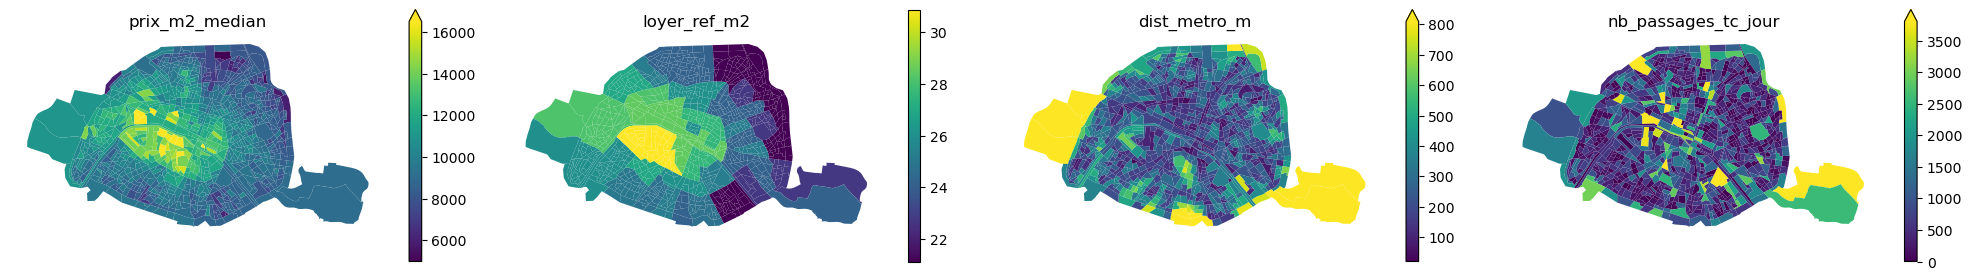

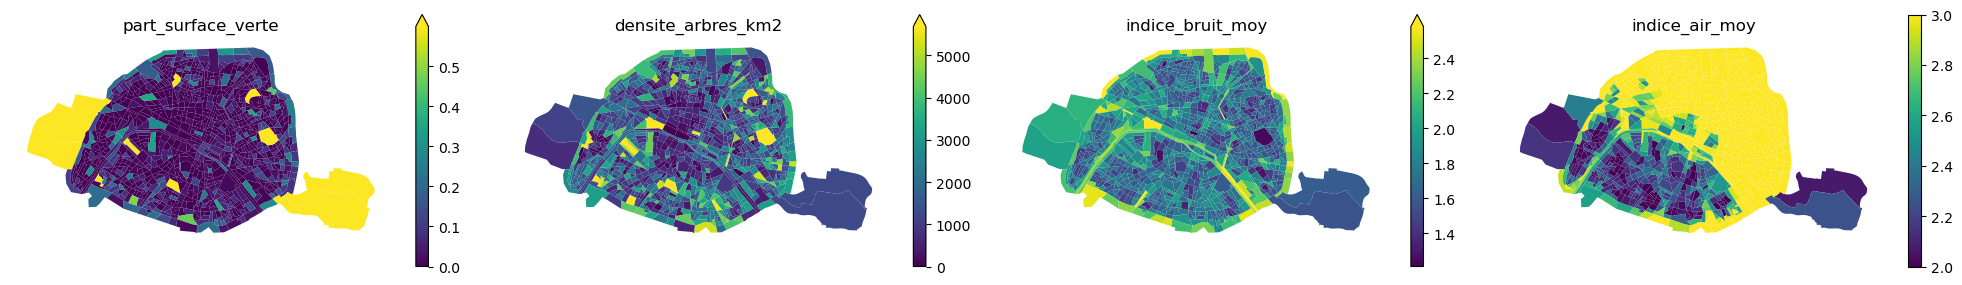

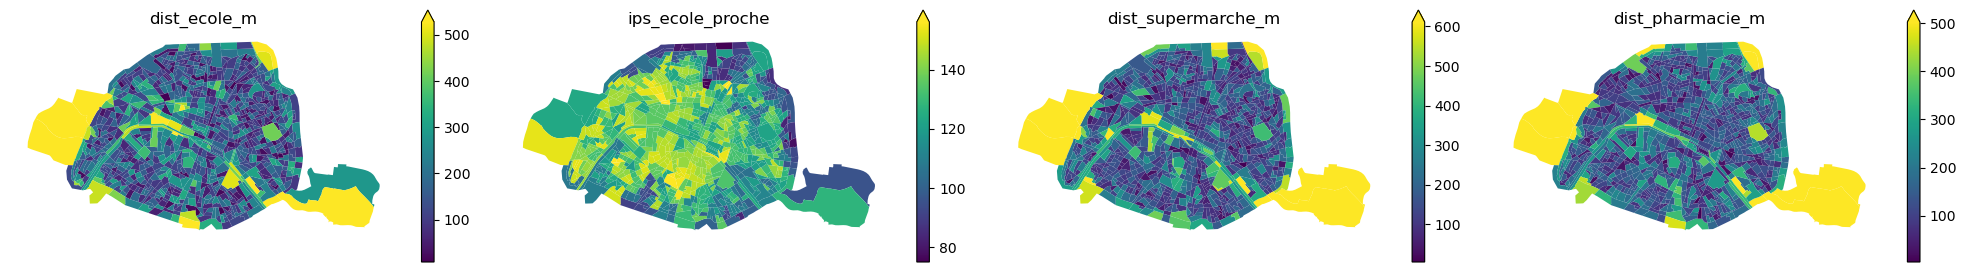

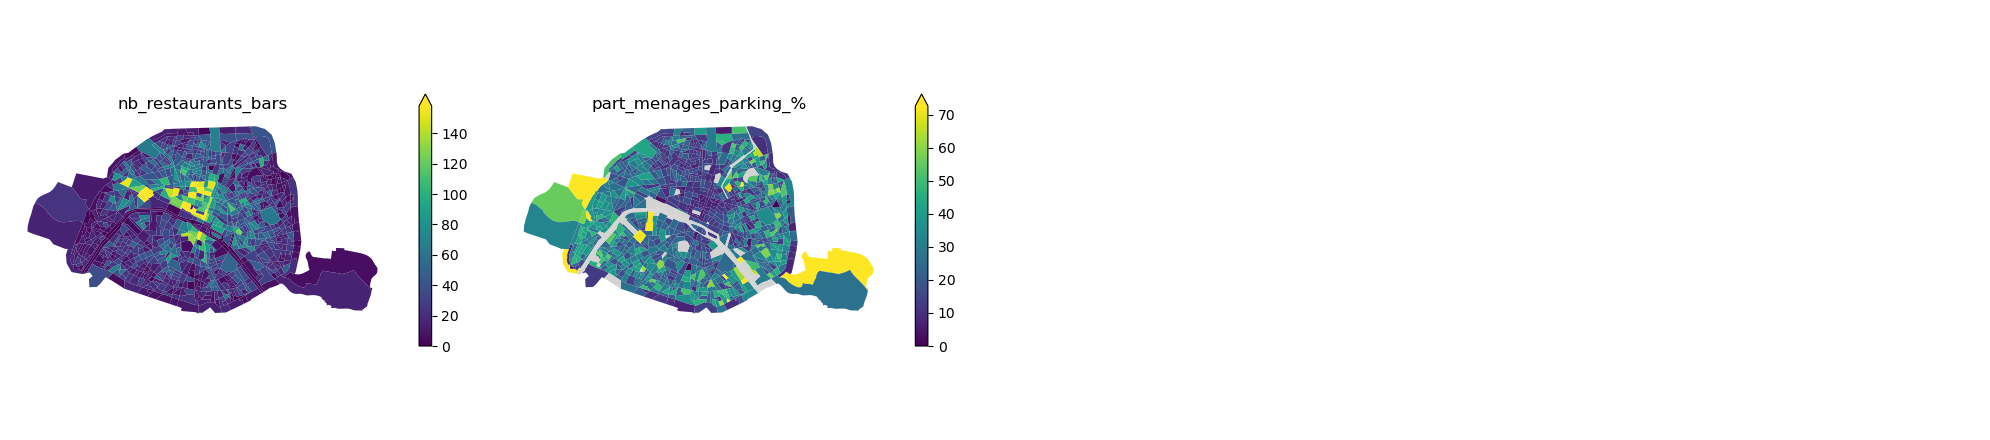

In [20]:
cols = ["prix_m2_median", "loyer_ref_m2", "dist_metro_m", "nb_passages_tc_jour",
        "part_surface_verte", "densite_arbres_km2", "indice_bruit_moy", "indice_air_moy",
        "dist_ecole_m", "ips_ecole_proche", "dist_supermarche_m", "dist_pharmacie_m",
        "nb_restaurants_bars", "part_menages_parking_%"]
for debut in range(0, len(cols), 4): 
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for ax, col in zip(axes, cols[debut:debut + 4]):
        if pd.api.types.is_numeric_dtype(iris_features[col]):
            # échelle coupée au 99e centile : sinon quelques IRIS extrêmes écrasent toutes les couleurs
            iris_features.plot(column=col, ax=ax, legend=True, vmax=iris_features[col].quantile(0.99),
                               missing_kwds={"color": "lightgrey"}, legend_kwds={"shrink": 0.6})
        else:
            iris_features.plot(column=col, ax=ax, categorical=True, cmap="tab20", missing_kwds={"color": "lightgrey"})
        ax.set_title(col)
    for ax in axes:
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

In [21]:
os.makedirs(SAVE_DIR, exist_ok=True)
iris_features.to_file(os.path.join(SAVE_DIR, "iris_features.geojson"), driver="GeoJSON")
iris_features.to_parquet(os.path.join(SAVE_DIR, "iris_features.parquet"), index=False)
iris_features.drop(columns="geometry").to_csv(os.path.join(SAVE_DIR, "iris_features.csv"), sep=";", index=False)